# Alunos:

-Alice De Muylder 

-Valmir Cerutti 

-Tiago Abreu

> **Integração com o repositório.** Este notebook é a Fase 1 do grupo e continua autossuficiente. O pipeline em `src/` reproduz exatamente este dataset (perfil `pulse` de `src/build_dataset.py`: mesmas células, semanas, rótulo e divisão) e acrescenta features de janela para a MLP; os modelos da Fase 2 são treinados por `src/train_nn.py`. Se `data/raw/usgs_m40_min.csv` existir (gerado por `src/download_usgs.py`), a seção 4 reaproveita o catálogo em vez de baixar mês a mês. Pode ser executado da raiz do projeto ou de dentro de `notebooks/`.

# SeismicAI — Fase 1: Definição do problema e preparação dos dados

**Produto:** *SeismicAI Pulse* — mapa semanal com a **probabilidade de ocorrência de terremotos de magnitude ≥ 4,0** em cada área do Círculo de Fogo do Pacífico.

## 1. Definição do problema

### 1.1 Contexto e motivação
Terremotos não podem ser previstos de forma determinística (dia, local e magnitude exatos). Mas a sismicidade **não é aleatória**: ela se concentra em regiões conhecidas e se agrupa no tempo — um evento costuma ser seguido de réplicas, e períodos de atividade elevada tendem a se prolongar e a se espalhar para áreas vizinhas. Isso torna possível estimar, de forma probabilística, **onde a atividade de curto prazo está mais provável**.

Hoje essa informação existe de forma dispersa (catálogos de eventos e modelos de risco de longo prazo, na escala de décadas). Falta uma visão simples, de **curto prazo e por área**, que responda: *"nesta semana, quais regiões estão com probabilidade elevada de terremotos?"*

### 1.2 Pergunta de pesquisa
> **Uma rede neural recorrente, treinada com o histórico sísmico recente de uma área e de seus vizinhos, estima a probabilidade de ocorrer pelo menos um terremoto de magnitude ≥ 4,0 nessa área na semana seguinte melhor do que estimativas estatísticas simples?**

### 1.3 Definição formal
- A região é dividida em células $c$ de 2° × 2°, e o tempo em semanas $t$.
- **Entrada:** $\mathbf{x}_{c,\,t-51:t} \in \mathbb{R}^{52 \times 7}$ (52 semanas de histórico da célula e dos vizinhos) e $\mathbf{s}_c \in \mathbb{R}^{4}$ (atributos fixos da célula).
- **Saída (rótulo):** $y_{c,\,t+1} = 1$ se houver **pelo menos um evento com M ≥ 4,0** na célula $c$ durante a semana $t+1$; caso contrário, $y_{c,\,t+1} = 0$.
- **Modelo:** $\hat{p}_{c,\,t+1} = f_\theta(\mathbf{x}_{c,\,t-51:t},\, \mathbf{s}_c) \in [0, 1]$ — a probabilidade estimada do evento.

### 1.4 Ficha do problema

| Item | Definição |
|---|---|
| **Tipo de problema** | Classificação binária probabilística sobre séries temporais (classes desbalanceadas). |
| **Público-alvo** | Seguradoras e resseguradoras (acompanhamento de exposição de curto prazo); defesa civil e operadores de infraestrutura crítica — energia, portos, mineração (priorização de inspeções e prontidão); jornalismo e divulgação científica. |
| **Região** | Círculo de Fogo do Pacífico, delimitado por 12 caixas de latitude/longitude (seção 3), dividido em células de 2° × 2°. Entram as células com ≥ 10 eventos M ≥ 4,0 no período de treino. |
| **Período** | 01/01/2000 a 31/12/2025, agregado em semanas (segunda a domingo, UTC). |
| **Fonte** | USGS ComCat, via FDSN Event Web Service (`/fdsnws/event/1/query`, formato CSV). |
| **Unidade de amostra** | Par (célula, semana). |
| **Entradas por semana (7)** | Nº de eventos M ≥ 4; magnitude máxima; energia sísmica liberada; nº de eventos M ≥ 5 (eventos grandes, que geram réplicas); semanas desde o último M ≥ 4; nº de eventos M ≥ 4 e M ≥ 5 nas 8 células vizinhas. |
| **Entradas fixas da célula (4)** | Latitude; seno e cosseno da longitude; taxa histórica de semanas com M ≥ 4 (calculada só no treino). |
| **Saída** | Probabilidade de ≥ 1 evento M ≥ 4,0 na célula na semana seguinte. |
| **Arquitetura prevista (Fase 2)** | LSTM sobre a sequência de 52 semanas, com os atributos fixos concatenados antes da camada de saída; comparada com uma MLP e com baselines estatísticos. |
| **Métricas** | ROC-AUC, PR-AUC (principal, por causa do desbalanceamento), F1 com limiar escolhido na validação, e curva de calibração. |

### 1.5 Por que magnitude ≥ 4,0
- **Relevância:** é a faixa em que terremotos passam a ser sentidos com clareza pela população e podem causar danos leves; também funciona como indicador de que uma área entrou em período de atividade.
- **Volume de dados:** eventos M ≥ 4 são muito mais frequentes que os de M ≥ 5. Isso gera mais exemplos positivos para o treino e deixa o desbalanceamento menos extremo.
- **Confiabilidade e período:** o período começa em **2000**, quando a rede sismográfica global já estava praticamente montada. Antes disso, muitos eventos M4 em regiões com poucas estações não foram registrados, e a rede aprenderia uma "queda de atividade" que é só falha de medição. Mesmo depois de 2000, algumas áreas remotas podem ter eventos M4 faltando nos primeiros anos; por isso o notebook faz um **diagnóstico de completude por segmento** (seção 6.1) e permite começar um segmento mais tarde, se necessário. O período longo também traz mais episódios de grande atividade (Sumatra 2004, Chile 2010, Japão 2011) para o modelo aprender.

### 1.6 Hipóteses
- **H1 — agrupamento temporal:** atividade recente na célula (sobretudo após eventos grandes) aumenta a probabilidade de novos eventos na semana seguinte.
- **H2 — contágio espacial:** atividade nas células vizinhas também aumenta essa probabilidade.
- **H3 — ganho da rede:** a LSTM combina esses sinais melhor do que regras estatísticas simples.

### 1.7 Critério de sucesso
O modelo será considerado útil se, **no conjunto de teste (2021–2025)**:
1. tiver **PR-AUC e ROC-AUC maiores que o melhor baseline** da seção 11 (taxa histórica, persistência, taxa recente ou combinado); e
2. for **bem calibrado** — quando estima 30%, o evento ocorre em aproximadamente 30% dos casos.

### 1.8 Fora do escopo
- Prever o **momento exato**, o **local exato** ou a **magnitude** de um terremoto.
- Funcionar como **sistema de alerta** ou substituir órgãos oficiais de monitoramento (seção 9 do enunciado).
- Estimar **danos** ou intensidade sentida.

## 2. Critérios de preparação e limpeza

1. Baixar o catálogo **global** mês a mês, M ≥ 4,0 (limite de 20.000 eventos por consulta; se atingir, divide o intervalo). A região é filtrada depois, o que facilita lidar com a linha de data (±180°).
2. Manter só `type = earthquake`; remover duplicatas por `id` e eventos sem tempo, coordenadas ou magnitude.
3. **Limiar de magnitude 4,0 e início em 2000**, com **diagnóstico de completude por segmento**: compara-se, ano a ano, a razão entre eventos M 4,0–4,4 e M ≥ 4,5. Pela lei de Gutenberg–Richter essa razão é aproximadamente constante (≈ 2); se ela cai nos primeiros anos de um segmento, faltam eventos pequenos ali, e o segmento passa a começar mais tarde (`SEGMENT_START`).
4. Atribuir cada evento a uma célula 2° × 2° e a uma semana (início segunda-feira, UTC).
5. Manter as células do Círculo de Fogo com **≥ 10 eventos** no período de treino.
6. **Réplicas são mantidas:** fazem parte da dinâmica real de curto prazo; o quanto do desempenho vem delas é analisado na Fase 2.
7. Transformações: log em contagens e energia; "semanas desde o último M ≥ 4" limitado a 260 (5 anos) e normalizado.
8. **Divisão temporal pela semana do rótulo:** treino 2001–2017 (2000 serve só de histórico inicial), validação 2018–2020, teste 2021–2025.
9. Padronização com média e desvio **somente do treino**.

In [17]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Configuração

In [18]:
import io, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

BASE_URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
START, END = "2000-01-01", "2026-01-01"     # END exclusivo
MC = 4.0             # magnitude mínima baixada/usada
TARGET_MAG = 4.0     # evento-alvo (rótulo)
BIG_MAG = 5.0        # "evento grande" (atributo de entrada)
CELL = 2.0           # tamanho da célula em graus
SEQ_LEN = 52         # semanas de histórico por amostra
MIN_TRAIN_EVENTS = 10
TRAIN_END, VAL_END = "2017-12-31", "2020-12-31"
# Início específico por segmento, caso o diagnóstico de completude (seção 6.1) indique falta de eventos
# nos primeiros anos. Ex.: {"Indonésia e Papua-Nova Guiné": "2005-01-01"}. Vazio = todos começam em START.
SEGMENT_START = {}
USGS_LIMIT = 20000

# Círculo de Fogo: caixas (lat_min, lat_max, lon_min, lon_max). Longitudes em [-180, 180].
RING_BOXES = {
    "Andes (Chile–Colômbia)":          (-60, 15, -85, -65),
    "América Central e México":        (5, 33, -118, -77),
    "Costa oeste EUA/Canadá":          (33, 60, -135, -114),
    "Alasca e Aleutas (leste)":        (50, 66, -180, -135),
    "Aleutas (oeste)":                 (48, 60, 160, 180),
    "Kamchatka e Kurilas":             (40, 62, 140, 165),
    "Japão":                           (24, 46, 125, 150),
    "Izu–Bonin e Marianas":            (10, 35, 135, 150),
    "Taiwan e Filipinas":              (4, 26, 115, 130),
    "Indonésia e Papua-Nova Guiné":    (-12, 6, 95, 155),
    "Melanésia, Tonga, Kermadec, NZ":  (-50, -4, 150, 180),
    "Tonga/Samoa (oeste da linha)":    (-30, -10, -180, -170),
}

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent   # raiz do projeto ou notebooks/
DATA = ROOT / "data"; RAW = DATA / "raw"; OUT = DATA / "processed"; FIG = ROOT / "results" / "eda"
for d in (RAW, OUT, FIG): d.mkdir(parents=True, exist_ok=True)

## 4. Download do catálogo USGS

Cada mês fica salvo em `data/raw/`. Se a execução cair, é só rodar de novo que continua de onde parou. Espere alguns minutos (são ~312 consultas).

In [19]:
def fetch_range(start, end):
    params = dict(format="csv", starttime=start.isoformat(), endtime=end.isoformat(),
                  minmagnitude=MC, eventtype="earthquake", orderby="time-asc", limit=USGS_LIMIT)
    for attempt in range(5):
        try:
            r = requests.get(BASE_URL, params=params, timeout=120)
            if r.status_code == 204 or not r.text.strip():
                return pd.DataFrame()
            r.raise_for_status()
            return pd.read_csv(io.StringIO(r.text))
        except requests.RequestException as e:
            wait = 2 ** attempt
            print(f"  erro ({e}); nova tentativa em {wait}s"); time.sleep(wait)
    raise RuntimeError(f"Falha ao baixar {start} – {end}")


def fetch_safe(start, end):
    df = fetch_range(start, end)
    if len(df) >= USGS_LIMIT:                       # atingiu o limite: divide o intervalo
        mid = start + (end - start) / 2
        return pd.concat([fetch_safe(start, mid), fetch_safe(mid, end)], ignore_index=True)
    return df

In [20]:
project_csv = RAW / "usgs_m40_min.csv"          # catálogo já baixado por src/download_usgs.py (M>=4,0 desde 2000)
months = pd.date_range(START, END, freq="MS") if not project_csv.exists() else []
for a, b in zip(months[:-1], months[1:]):
    f = RAW / f"usgs_{a:%Y_%m}.csv"
    if f.exists():
        continue
    df_m = fetch_safe(a, b)
    df_m.to_csv(f, index=False)
    print(f"{a:%Y-%m}: {len(df_m):>5} eventos")
    time.sleep(0.3)

if project_csv.exists():
    raw = pd.read_csv(project_csv)
    print(f"usando o catálogo do projeto: {project_csv.name}")
else:
    raw = pd.concat([pd.read_csv(f) for f in sorted(RAW.glob("usgs_????_??.csv")) if f.stat().st_size > 1],
                    ignore_index=True)
print(raw.shape)
raw.head()

(358673, 22)


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2000-01-01T01:19:26.990Z,41.927,20.543,10.0,4.5,mb,NaN,NaN,NaN,1.14,...,2014-11-07T01:09:14.397Z,"14 km SW of Dragash, Kosovo",earthquake,NaN,NaN,NaN,18.0,reviewed,us,us
1,2000-01-01T02:12:13.450Z,-11.348,164.568,33.0,4.3,mb,NaN,NaN,NaN,1.16,...,2014-11-07T01:09:14.702Z,"150 km WSW of Lata, Solomon Islands",earthquake,NaN,NaN,NaN,2.0,reviewed,us,us
2,2000-01-01T04:30:10.370Z,-26.012,-68.803,105.0,4.5,mb,NaN,NaN,NaN,0.91,...,2014-11-07T01:09:14.812Z,"130 km ENE of Diego de Almagro, Chile",earthquake,NaN,NaN,NaN,15.0,reviewed,us,us
3,2000-01-01T05:24:35.290Z,36.874,69.947,54.3,5.1,mwc,NaN,NaN,NaN,0.83,...,2022-04-29T18:27:48.504Z,"29 km SSE of Rust?q, Afghanistan",earthquake,NaN,12.7,NaN,NaN,reviewed,us,hrv
4,2000-01-01T05:58:19.780Z,-60.722,153.670,10.0,6.0,mwc,NaN,NaN,NaN,1.05,...,2022-04-29T18:27:54.065Z,west of Macquarie Island,earthquake,NaN,NaN,NaN,NaN,reviewed,us,hrv


## 5. Limpeza

In [21]:
df = raw.copy(); log = {f"bruto (global, M>={MC})": len(df)}
df = df.drop_duplicates(subset="id");                                   log["sem duplicatas"] = len(df)
df = df[df["type"] == "earthquake"];                                    log["type = earthquake"] = len(df)
df = df.dropna(subset=["time", "latitude", "longitude", "mag"]);        log["sem nulos essenciais"] = len(df)
df = df[df["mag"] >= MC];                                               log[f"mag >= {MC}"] = len(df)

df["time"] = pd.to_datetime(df["time"], utc=True, format="ISO8601")
df = df[(df.time >= pd.Timestamp(START, tz="UTC")) & (df.time < pd.Timestamp(END, tz="UTC"))]
df["longitude"] = ((df["longitude"] + 180) % 360) - 180
df = df.sort_values("time").reset_index(drop=True)

# Célula 2x2 (grade global) e semana
NLAT, NLON = int(180 / CELL), int(360 / CELL)
df["ci"] = np.clip(((df.latitude + 90) // CELL).astype(int), 0, NLAT - 1)
df["cj"] = np.clip(((df.longitude + 180) // CELL).astype(int), 0, NLON - 1)
T0 = pd.Timestamp(START, tz="UTC") - pd.Timedelta(days=pd.Timestamp(START).dayofweek)   # segunda-feira <= START
df["week"] = ((df.time - T0).dt.days // 7).astype(int)
W = int((pd.Timestamp(END, tz="UTC") - T0).days // 7) + 1
week_start = pd.date_range(T0, periods=W, freq="7D")

display(pd.Series(log, name="eventos").to_frame())

,eventos
"bruto (global, M>=4.0)",358673
sem duplicatas,358673
type = earthquake,358673
sem nulos essenciais,358673
mag >= 4.0,358672


## 6. Células do Círculo de Fogo

In [22]:
def in_ring(lat, lon):
    lat, lon = np.asarray(lat), np.asarray(lon)
    m = np.zeros(lat.shape, bool)
    for la0, la1, lo0, lo1 in RING_BOXES.values():
        m |= (lat >= la0) & (lat < la1) & (lon >= lo0) & (lon < lo1)
    return m

train_week_end = int((pd.Timestamp(TRAIN_END, tz="UTC") - T0).days // 7)
cell_lat = -90 + (np.arange(NLAT) + 0.5) * CELL
cell_lon = -180 + (np.arange(NLON) + 0.5) * CELL

ev_train = df[df.week <= train_week_end]
cnt = ev_train.groupby(["ci", "cj"]).size()
cells = cnt[cnt >= MIN_TRAIN_EVENTS].reset_index()[["ci", "cj"]]
cells["lat"] = cell_lat[cells.ci]; cells["lon"] = cell_lon[cells.cj]
cells = cells[in_ring(cells.lat, cells.lon)].reset_index(drop=True)
NC = len(cells)
print(f"{NC} células ativas no Círculo de Fogo")

df["in_ring"] = in_ring(df.latitude, df.longitude)
print(f"Eventos M>={MC} dentro das caixas do Círculo de Fogo: {df.in_ring.mean():.1%} do catálogo global")

709 células ativas no Círculo de Fogo
Eventos M>=4.0 dentro das caixas do Círculo de Fogo: 73.8% do catálogo global


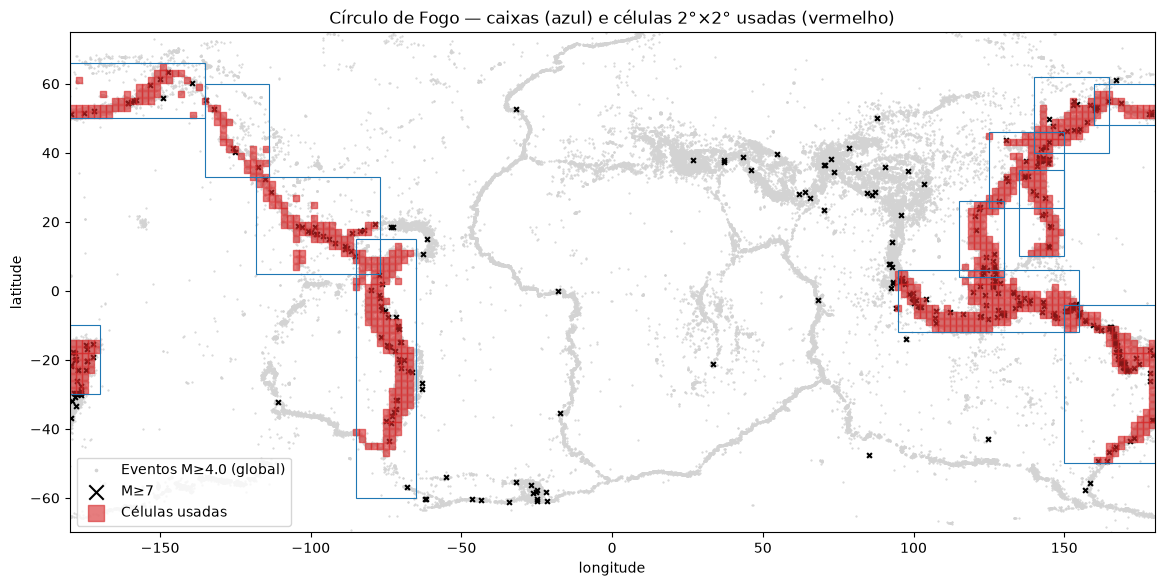

In [23]:
fig, ax = plt.subplots(figsize=(14, 6.5))
ax.scatter(df.longitude, df.latitude, s=0.3, c="lightgray", label=f"Eventos M≥{MC} (global)")
big = df[df.mag >= 7]
ax.scatter(big.longitude, big.latitude, s=12, c="black", marker="x", label="M≥7")
ax.scatter(cells.lon, cells.lat, s=14, marker="s", c="tab:red", alpha=.6, label="Células usadas")
for la0, la1, lo0, lo1 in RING_BOXES.values():
    ax.add_patch(plt.Rectangle((lo0, la0), lo1 - lo0, la1 - la0, fill=False, ec="tab:blue", lw=.8))
ax.set(xlim=(-180, 180), ylim=(-70, 75), xlabel="longitude", ylabel="latitude",
       title="Círculo de Fogo — caixas (azul) e células 2°×2° usadas (vermelho)")
ax.legend(loc="lower left", markerscale=3); plt.savefig(FIG / "mapa_celulas.png", dpi=120); plt.show()

### 6.1 Diagnóstico de completude por segmento

Pela lei de Gutenberg–Richter, para cada evento M ≥ 4,5 esperam-se cerca de **2 eventos entre 4,0 e 4,4** (com b ≈ 1). Essa razão não depende de a região estar mais ou menos ativa, então serve para detectar **falta de registro**: se ela é bem menor em certos anos, o catálogo está incompleto ali.

Se algum segmento aparecer como suspeito, defina `SEGMENT_START` na configuração (seção 3) e rode o notebook de novo.

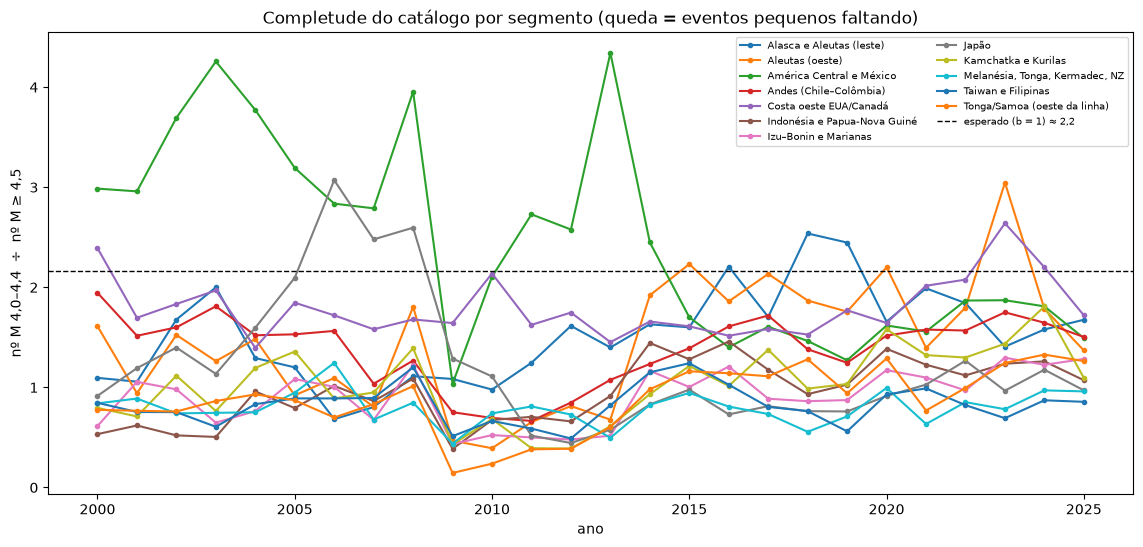

C:\Users\02743894601\AppData\Local\Temp\ipykernel_21368\2883638164.py:24: Pandas4Warning: Starting with pandas version 4.0 all arguments of median will be keyword-only.
  ref = ratio.loc[:, ratio.columns >= 2015].median(1)
C:\Users\02743894601\AppData\Local\Temp\ipykernel_21368\2883638164.py:25: Pandas4Warning: Starting with pandas version 4.0 all arguments of median will be keyword-only.
  early = ratio.loc[:, ratio.columns <= 2005].median(1)


,razão 2000–2005,razão 2015+,relativo,suspeito
segmento,,,,
Indonésia e Papua-Nova Guiné,0.58,1.23,0.47,True
Tonga/Samoa (oeste da linha),0.82,1.16,0.71,False
Alasca e Aleutas (leste),1.25,1.70,0.73,False
Aleutas (oeste),1.37,1.86,0.74,False
Kamchatka e Kurilas,0.96,1.30,0.74,False
Izu–Bonin e Marianas,0.87,1.10,0.79,False
Taiwan e Filipinas,0.79,0.86,0.93,False
"Melanésia, Tonga, Kermadec, NZ",0.80,0.81,0.98,False
Andes (Chile–Colômbia),1.57,1.57,1.00,False


Segmentos suspeitos (avaliar SEGMENT_START): ['Indonésia e Papua-Nova Guiné']


,nº de células
segmento,
Indonésia e Papua-Nova Guiné,140
Andes (Chile–Colômbia),128
"Melanésia, Tonga, Kermadec, NZ",77
Japão,62
América Central e México,60
Alasca e Aleutas (leste),49
Kamchatka e Kurilas,47
Taiwan e Filipinas,43
Tonga/Samoa (oeste da linha),31


In [24]:
def segment_of(lat, lon):
    lat, lon = np.asarray(lat), np.asarray(lon)
    seg = np.full(lat.shape, None, object)
    for name, (la0, la1, lo0, lo1) in RING_BOXES.items():
        m = (seg == None) & (lat >= la0) & (lat < la1) & (lon >= lo0) & (lon < lo1)
        seg[m] = name
    return seg

ev = df[df.in_ring].copy()
ev["segmento"] = segment_of(ev.latitude, ev.longitude)
ev["ano"] = ev.time.dt.year
ev["faixa"] = np.where(ev.mag < 4.5, "m40_44", "m45")
tab = ev.pivot_table(index="segmento", columns=["ano", "faixa"], values="id", aggfunc="count", fill_value=0)
ratio = tab.xs("m40_44", axis=1, level="faixa") / tab.xs("m45", axis=1, level="faixa").replace(0, np.nan)

fig, ax = plt.subplots(figsize=(14, 6))
for seg in ratio.index:
    ax.plot(ratio.columns, ratio.loc[seg], marker="o", ms=3, label=seg)
ax.axhline(10 ** 0.5 - 1, c="k", ls="--", lw=1, label="esperado (b = 1) ≈ 2,2")
ax.set(xlabel="ano", ylabel="nº M 4,0–4,4  ÷  nº M ≥ 4,5",
       title="Completude do catálogo por segmento (queda = eventos pequenos faltando)")
ax.legend(fontsize=7, ncol=2); plt.savefig(FIG / "completude_segmentos.png", dpi=120); plt.show()

ref = ratio.loc[:, ratio.columns >= 2015].median(1)
early = ratio.loc[:, ratio.columns <= 2005].median(1)
diag = pd.DataFrame({"razão 2000–2005": early, "razão 2015+": ref, "relativo": early / ref}).round(2)
diag["suspeito"] = diag["relativo"] < 0.7
display(diag.sort_values("relativo"))
print("Segmentos suspeitos (avaliar SEGMENT_START):", diag.index[diag.suspeito].tolist() or "nenhum")

# Semana inicial válida de cada célula (START ou o início definido para o seu segmento)
cells["segmento"] = segment_of(cells.lat, cells.lon)
cell_start = np.array([max(0, (pd.Timestamp(SEGMENT_START.get(sg, START), tz="UTC") - T0).days // 7)
                       for sg in cells.segmento])
display(cells.segmento.value_counts().to_frame("nº de células"))

## 7. Agregação semanal por célula

Primeiro em grade global (necessária para os vizinhos), depois recortada nas células ativas.

In [25]:
E = 10 ** (1.5 * df.mag + 4.8)                 # energia (J), relação de Gutenberg–Richter
E_REF = 10 ** (1.5 * MC + 4.8)
df["E"] = E
df["is_t"] = (df.mag >= TARGET_MAG).astype(int)
df["is_big"] = (df.mag >= BIG_MAG).astype(int)

g = df.groupby(["ci", "cj", "week"])
agg = pd.DataFrame({"n": g.size(), "maxmag": g.mag.max(), "E": g.E.sum(),
                    "nt": g.is_t.sum(), "nb": g.is_big.sum()}).reset_index()

grid_n  = np.zeros((NLAT, NLON, W), np.float32)   # eventos M>=MC
grid_nb = np.zeros((NLAT, NLON, W), np.float32)   # eventos grandes M>=BIG_MAG
grid_n [agg.ci, agg.cj, agg.week] = agg.n
grid_nb[agg.ci, agg.cj, agg.week] = agg.nb

def neighbors_sum(G):
    # soma das 8 células vizinhas (longitude dá a volta em ±180°)
    S = np.zeros_like(G)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == dj == 0: continue
            sh = np.roll(G, dj, axis=1)
            if di == 1:  sh = np.concatenate([np.zeros_like(sh[:1]), sh[:-1]], 0)
            if di == -1: sh = np.concatenate([sh[1:], np.zeros_like(sh[:1])], 0)
            S += sh
    return S

nb_n, nb_nb = neighbors_sum(grid_n), neighbors_sum(grid_nb)

ci, cj = cells.ci.values, cells.cj.values
n, nbig = grid_n[ci, cj], grid_nb[ci, cj]                  # [NC, W]
maxmag = np.zeros((NC, W), np.float32); Esum = np.zeros((NC, W), np.float32)
nt = np.zeros((NC, W), np.float32)                          # eventos-alvo M>=TARGET_MAG
pos = {(a, b): k for k, (a, b) in enumerate(zip(ci, cj))}
sub = agg[[(a, b) in pos for a, b in zip(agg.ci, agg.cj)]]
k = np.array([pos[(a, b)] for a, b in zip(sub.ci, sub.cj)], int)
maxmag[k, sub.week] = sub.maxmag; Esum[k, sub.week] = sub.E; nt[k, sub.week] = sub.nt

# semanas desde o último evento-alvo (causal: usa até a semana t, inclusive)
since = np.zeros((NC, W), np.float32); last = np.full(NC, -10**6)
for t in range(W):
    last = np.where(nt[:, t] > 0, t, last)
    since[:, t] = np.minimum(t - last, 260)

FEAT_NAMES = ["log_n", "maxmag_exc", "log_energia", "log_n_grandes", "semanas_desde_alvo",
              "log_viz_n", "log_viz_grandes"]
X = np.stack([np.log1p(n),
              np.where(n > 0, maxmag - (MC - 0.5), 0),
              np.log10(1 + Esum / E_REF),
              np.log1p(nbig),
              since / 260,
              np.log1p(nb_n[ci, cj]),
              np.log1p(nb_nb[ci, cj])], axis=-1).astype(np.float32)     # [NC, W, F]
Y = (nt > 0).astype(np.int8)                                              # [NC, W]
print("X:", X.shape, " Y:", Y.shape)

X: (709, 1358, 7)  Y: (709, 1358)


## 8. Amostras e divisão temporal

A amostra `(c, t)` usa as semanas `t-51 … t` como entrada e `Y[c, t+1]` como rótulo. A divisão é feita pela data da semana do rótulo.

In [26]:
week_of = lambda d: int((pd.Timestamp(d, tz="UTC") - T0).days // 7)
w_train_end, w_val_end = week_of(TRAIN_END), week_of(VAL_END)
w_last = week_of(END) - 1                                   # última semana completa

t_all = np.arange(SEQ_LEN - 1, w_last)                      # t = última semana de entrada
lab = t_all + 1
splits = {"train": t_all[lab <= w_train_end],
          "val":   t_all[(lab > w_train_end) & (lab <= w_val_end)],
          "test":  t_all[(lab > w_val_end) & (lab <= w_last)]}
idx = {}
for s, ts in splits.items():
    I = np.stack([np.tile(np.arange(NC), len(ts)), np.repeat(ts, NC)], 1).astype(np.int32)
    idx[s] = I[I[:, 1] - SEQ_LEN + 1 >= cell_start[I[:, 0]]]   # janela inteira dentro do período válido da célula

valid_week = np.arange(W)[None, :] >= cell_start[:, None]       # [NC, W]

# atributos fixos da célula (taxa histórica calculada SÓ com semanas de treino)
vt = valid_week[:, :w_train_end + 1]
train_rate = (Y[:, :w_train_end + 1] * vt).sum(1) / np.maximum(vt.sum(1), 1)
STATIC_NAMES = ["lat_norm", "sin_lon", "cos_lon", "taxa_hist_treino"]
static = np.stack([cells.lat / 90, np.sin(np.radians(cells.lon)), np.cos(np.radians(cells.lon)),
                   train_rate], 1).astype(np.float32)

rows = []
for s, I in idx.items():
    yy = Y[I[:, 0], I[:, 1] + 1]
    rows.append({"split": s, "semanas": len(splits[s]), "amostras": len(I),
                 "positivos": int(yy.sum()), "% positivos": yy.mean()})
display(pd.DataFrame(rows).set_index("split").style.format({"% positivos": "{:.2%}", "amostras": "{:,}"}))

,semanas,amostras,positivos,% positivos
split,,,,
train,888,"629,592",91523,14.54%
val,157,"111,313",17716,15.92%
test,260,"184,340",30682,16.64%


### 8.1 Leitura da tabela

- **Tamanho:** o número de amostras é exatamente `células × semanas` (709 × 888 = 629.592 no treino; 709 × 157 = 111.313 na validação; 709 × 260 = 184.340 no teste). Ou seja, nenhuma célula foi cortada no início — `SEGMENT_START` está vazio.
- **Desbalanceamento:** só **~15–17%** das amostras são positivas (≈ 1 positivo para 5,5 negativos). Por isso a acurácia não serve como métrica: um modelo que sempre diz "não" acerta ~84%. As métricas principais serão **PR-AUC** (cujo valor de um classificador aleatório é a própria taxa de positivos, ~0,16) e ROC-AUC. Na Fase 2, isso sugere `pos_weight ≈ 538.069 / 91.523 ≈ 5,9` na função de perda (negativos ÷ positivos do treino).
- **Deriva temporal:** a taxa de positivos **sobe** ao longo do tempo (14,5% → 15,9% → 16,6%). Parte disso é atividade real (grandes sequências no período de teste), mas parte vem da **melhora na detecção de eventos M 4,0–4,4**, visível no diagnóstico de completude (seção 6.1). Consequência prática: um modelo calibrado no treino tende a **subestimar** levemente as probabilidades no teste, o que deve aparecer na curva de calibração.
- **Ponto em aberto:** o diagnóstico da seção 6.1 marcou **Indonésia e Papua-Nova Guiné** como suspeito (razão relativa 0,47), mas o segmento não foi ajustado. Vale testar `SEGMENT_START = {"Indonésia e Papua-Nova Guiné": "2006-01-01"}` e comparar os resultados — esse é o segmento com mais células (140).

## 9. Padronização (estatísticas só do treino)

In [27]:
mask_train_weeks = np.zeros(W, bool); mask_train_weeks[: w_train_end + 1] = True
mu = X[:, mask_train_weeks].reshape(-1, X.shape[-1]).mean(0)
sd = X[:, mask_train_weeks].reshape(-1, X.shape[-1]).std(0) + 1e-6
Xs = (X - mu) / sd
display(pd.DataFrame({"média_treino": mu, "desvio_treino": sd}, index=FEAT_NAMES).round(3))

,média_treino,desvio_treino
log_n,0.127,0.343
maxmag_exc,0.157,0.422
log_energia,0.148,0.442
log_n_grandes,0.019,0.131
semanas_desde_alvo,0.129,0.241
log_viz_n,0.647,0.717
log_viz_grandes,0.119,0.324


## 10. Exploração

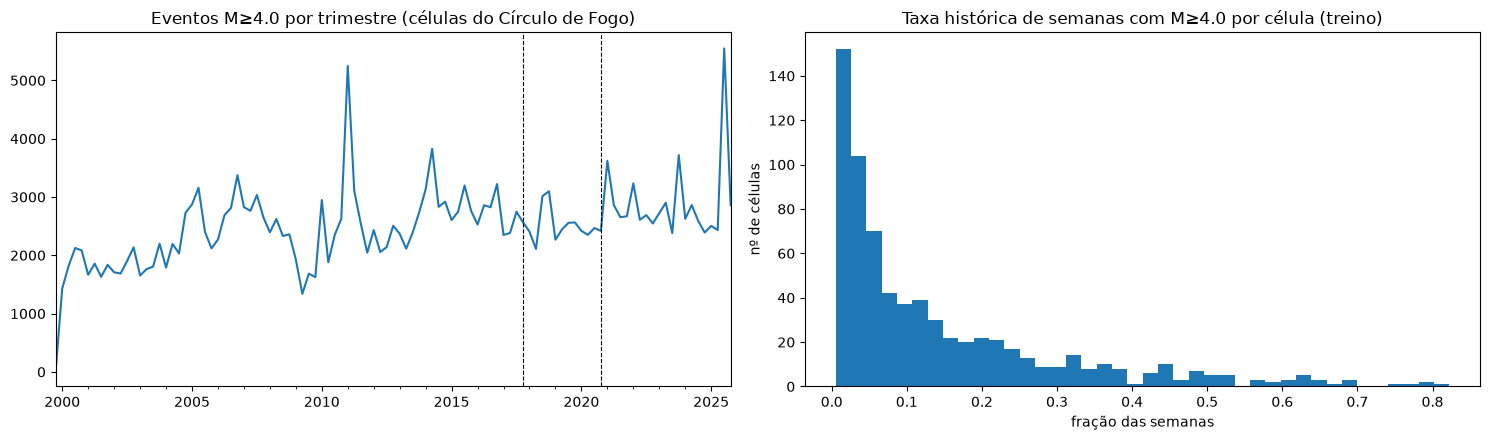

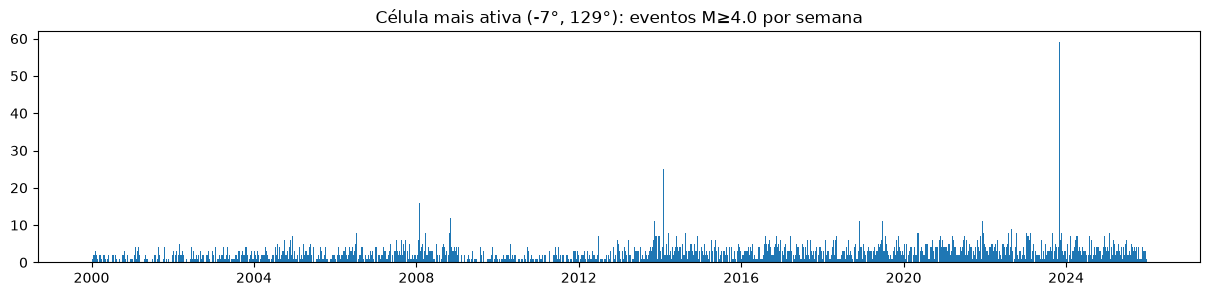

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
weekly = pd.Series(nt.sum(0), index=week_start).resample("QS").sum()
weekly.plot(ax=ax[0], title=f"Eventos M≥{TARGET_MAG} por trimestre (células do Círculo de Fogo)")
for d in [TRAIN_END, VAL_END]: ax[0].axvline(pd.Timestamp(d), c="k", ls="--", lw=.8)
ax[0].set(xlabel="trimestre", ylabel=f"nº de eventos M≥{TARGET_MAG}")

ax[1].hist(train_rate, bins=40)
ax[1].set(title=f"Taxa histórica de semanas com M≥{TARGET_MAG} por célula (treino)",
          xlabel="fração das semanas", ylabel="nº de células")
plt.tight_layout(); plt.savefig(FIG / "eda_series.png", dpi=120); plt.show()

# Exemplo: célula mais ativa — mostra o agrupamento temporal (réplicas)
c0 = int(np.argmax(train_rate))
fig, ax = plt.subplots(figsize=(15, 3))
ax.bar(week_start, n[c0], width=7)
ax.set(title=f"Célula mais ativa ({cells.lat[c0]:.0f}°, {cells.lon[c0]:.0f}°): eventos M≥{MC} por semana",
       xlabel="semana", ylabel=f"nº de eventos M≥{MC}")
plt.savefig(FIG / "eda_celula_exemplo.png", dpi=120); plt.show()

### 10.1 Análise dos gráficos

> Os rótulos dos eixos foram adicionados no código acima; **rode a célula de novo** para os gráficos salvos refletirem a mudança. O mapa (seção 6) e o diagnóstico de completude (6.1) já tinham eixos rotulados.

**Eventos por trimestre.** A série oscila em torno de 2.000–3.000 eventos por trimestre, com **picos curtos e altos** que correspondem a grandes terremotos e suas réplicas — o maior deles no início de 2011 (Tohoku, Japão) e outro em 2025, dentro do período de teste. Depois de cada pico a contagem volta ao patamar em poucos trimestres. Isso é o **agrupamento temporal** da hipótese H1: a atividade se concentra logo após eventos grandes. Também há uma **subida gradual de 2000 a ~2007** e uma queda isolada em 2009; as duas coincidem com mudanças de completude vistas na seção 6.1, então não devem ser lidas como mudança real da sismicidade.

**Taxa histórica por célula.** A distribuição é **fortemente assimétrica**: a maioria das células tem M ≥ 4 em menos de 5% das semanas, e poucas passam de 50% (até ~80%). Isso indica que **"onde" explica muito do problema** — saber quais células são cronicamente ativas já separa bem positivos de negativos. É por isso que o baseline de taxa histórica é forte (seção 11), e a rede só terá valor se acrescentar informação **temporal** (quando) a essa informação **espacial**.

**Célula mais ativa (−7°, 129°, Mar de Banda).** O fundo é de poucos eventos por semana, com **rajadas isoladas** (2008, 2014 e a maior, com ~60 eventos em uma semana no fim de 2023). Após cada rajada, a atividade fica acima do normal por algumas semanas. Esse é o padrão que a LSTM deve aprender: depois de um evento grande, a probabilidade da semana seguinte sobe. Nota-se ainda um nível de fundo maior a partir de ~2013, novamente compatível com melhora de detecção.

## 11. Baselines (a rede da Fase 2 precisa superar estes números)

| Baseline | Probabilidade prevista para a semana *t+1* |
|---|---|
| **Taxa histórica** | fração das semanas de treino em que a célula teve M ≥ 4 |
| **Persistência** | 1 se houve M ≥ 4 na semana *t*, senão 0 |
| **Taxa recente** | fração das últimas 52 semanas com M ≥ 4 |
| **Combinado** | média da taxa histórica e da taxa recente |

In [32]:
Yf = Y.astype(np.float32)
cum = np.concatenate([np.zeros((NC, 1)), np.cumsum(Yf, 1)], 1)
tt = np.arange(W)
recent = (cum[:, tt + 1] - cum[:, np.maximum(tt - SEQ_LEN + 1, 0)]) / SEQ_LEN   # fração das semanas t-51..t

def baselines(I):
    c, t = I[:, 0], I[:, 1]
    return {"Taxa histórica": train_rate[c], "Persistência": Yf[c, t],
            "Taxa recente (52 sem)": recent[c, t],
            "Combinado": 0.5 * train_rate[c] + 0.5 * recent[c, t]}, Y[c, t + 1]

res = []
for s in ["val", "test"]:
    preds, yy = baselines(idx[s])
    for name, p in preds.items():
        res.append({"split": s, "baseline": name, "ROC-AUC": roc_auc_score(yy, p),
                    "PR-AUC": average_precision_score(yy, p), "PR-AUC aleatório": yy.mean()})
base_df = pd.DataFrame(res)
display(base_df.pivot(index="baseline", columns="split", values=["ROC-AUC", "PR-AUC"]).round(3))

ROC-AUC        PR-AUC       
split                    test    val   test    val
baseline                                          
Combinado               0.836  0.832  0.552  0.536
Persistência            0.646  0.639  0.266  0.251
Taxa histórica          0.830  0.827  0.528  0.518
Taxa recente (52 sem)   0.831  0.826  0.541  0.522

### 11.1 Leitura dos baselines

| Baseline | ROC-AUC (val / teste) | PR-AUC (val / teste) |
|---|---|---|
| Persistência | 0,639 / 0,646 | 0,251 / 0,266 |
| Taxa histórica | 0,827 / 0,830 | 0,518 / 0,528 |
| Taxa recente (52 sem) | 0,826 / 0,831 | 0,522 / 0,541 |
| **Combinado** | **0,832 / 0,836** | **0,536 / 0,552** |
| *Aleatório* | *0,5* | *~0,16 / ~0,17* |

- **Todos superam o acaso**, o que confirma que há sinal a ser aprendido. A PR-AUC do baseline combinado (~0,55) é cerca de **3,3 vezes** a de um classificador aleatório (~0,17).
- **A taxa histórica sozinha chega a ROC-AUC 0,83.** Isso confirma a leitura da seção 10: a maior parte do poder preditivo vem de *qual célula* é, não de *qual semana*.
- **Persistência é o pior**, porque só dá 0 ou 1 e não ordena bem as amostras (ROC baixa). Mesmo assim, sua PR-AUC (0,27) fica bem acima do acaso — evidência direta de **H1 (agrupamento temporal)**: ter tido evento nesta semana aumenta a chance de ter na próxima.
- **A taxa recente acrescenta pouco à histórica** (+0,01 a +0,02 de PR-AUC) e o **combinado é o melhor**. Ou seja, olhar o passado recente ajuda, mas uma média simples aproveita pouco essa informação.
- O teste fica ligeiramente acima da validação, coerente com a maior taxa de positivos no teste (seção 8.1).

**Meta para a Fase 2:** a LSTM precisa superar o baseline **Combinado** — **ROC-AUC > 0,836 e PR-AUC > 0,552 no teste** (escolhendo hiperparâmetros só pela validação: 0,832 / 0,536). Como a margem sobre o "onde" é pequena, o ganho deve vir de sinais que os baselines ignoram: eventos grandes (M ≥ 5) recentes, atividade nos vizinhos (H2) e a forma da sequência das últimas 52 semanas.

## 12. Salvar o dataset pronto para a Fase 2

In [33]:
np.savez_compressed(OUT / "rof_dataset.npz", X=Xs.astype(np.float32), Y=Y, static=static,
                    idx_train=idx["train"], idx_val=idx["val"], idx_test=idx["test"])
cells.assign(taxa_hist_treino=train_rate).to_csv(OUT / "celulas.csv", index=False)
base_df.to_csv(OUT / "baselines.csv", index=False)

meta = {"descricao": f"P(>=1 evento M>={TARGET_MAG} na celula na semana t+1) | entrada: semanas t-{SEQ_LEN-1}..t",
        "X_shape [celulas, semanas, atributos]": list(Xs.shape),
        "atributos_por_semana": FEAT_NAMES, "atributos_fixos": STATIC_NAMES,
        "seq_len": SEQ_LEN, "celula_graus": CELL, "mag_min": MC, "mag_alvo": TARGET_MAG, "mag_grande": BIG_MAG,
        "semana_0": str(T0.date()), "split_por_semana_do_rotulo": {"train": f"ate {TRAIN_END}",
            "val": f"ate {VAL_END}", "test": f"ate {END} (exclusivo)"},
        "n_amostras": {s: int(len(I)) for s, I in idx.items()},
        "padronizacao": {"media": mu.tolist(), "desvio": sd.tolist()},
        "caixas_circulo_de_fogo": RING_BOXES, "inicio_por_segmento": SEGMENT_START, "limpeza": log}
(OUT / "metadata.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
print(json.dumps({k: meta[k] for k in ["X_shape [celulas, semanas, atributos]", "n_amostras"]}, indent=2))

{
  "X_shape [celulas, semanas, atributos]": [
    709,
    1358,
    7
  ],
  "n_amostras": {
    "train": 629592,
    "val": 111313,
    "test": 184340
  }
}


## 13. Como a Fase 2 vai consumir os dados

As janelas não são materializadas (seriam ~1 milhão × 52 × 7 valores). Um `Dataset` do PyTorch recorta cada janela na hora:

In [31]:
# Exemplo para a Fase 2 (não treina nada aqui)
try:
    import torch
    from torch.utils.data import Dataset

    class RingOfFireDataset(Dataset):
        def __init__(self, path, split, seq_len=SEQ_LEN):
            d = np.load(path)
            self.X, self.Y, self.S = torch.tensor(d["X"]), torch.tensor(d["Y"]), torch.tensor(d["static"])
            self.idx, self.L = d[f"idx_{split}"], seq_len
        def __len__(self): return len(self.idx)
        def __getitem__(self, i):
            c, t = self.idx[i]
            seq = self.X[c, t - self.L + 1 : t + 1]          # [52, 7]
            return seq, self.S[c], self.Y[c, t + 1].float()  # entrada, fixos, rótulo

    ds = RingOfFireDataset(OUT / "rof_dataset.npz", "train")
    seq, st, yy = ds[0]
    print(len(ds), "amostras de treino | seq", tuple(seq.shape), "| fixos", tuple(st.shape), "| y", yy.item())
except ImportError:
    print("PyTorch não instalado — exemplo pulado.")

629592 amostras de treino | seq (52, 7) | fixos (4,) | y 0.0


## 14. Notas para a Fase 2 e para o artigo

- **Métricas:** ROC-AUC e **PR-AUC** (mais informativa com classes desbalanceadas), F1 com limiar escolhido na validação, e **curva de calibração**: se o modelo diz 20%, o evento deve ocorrer em ~20% dos casos.
- **Desbalanceamento:** `BCEWithLogitsLoss(pos_weight=neg/pos)` ou amostragem balanceada no treino.
- **Comparação obrigatória:** LSTM × MLP (mesmas entradas achatadas) × baselines da seção 11.
- **Réplicas:** boa parte da previsibilidade vem de sequências de réplicas após grandes terremotos. Vale reportar o desempenho também em células/semanas **sem** evento grande (M ≥ 5) recente, para mostrar o que a rede aprende além disso.
- **Limitações:** catálogo global heterogêneo (tipos de magnitude diferentes, completude variável); células de 2° são grosseiras; semanas são um horizonte curto; não há física de falhas no modelo.
- **Uso responsável (seção 9 do enunciado):** os resultados são estimativas probabilísticas experimentais, não previsão determinística nem sistema de alerta.

## 15. Conclusões da Fase 1

1. **Problema bem definido e viável.** A tarefa — estimar a probabilidade de ≥ 1 evento M ≥ 4,0 em uma célula de 2° × 2° do Círculo de Fogo na semana seguinte — tem dados suficientes: 709 células, 1.358 semanas e ~925 mil amostras, com ~15–17% de positivos.
2. **Dados preparados sem vazamento.** A divisão é temporal (treino 2001–2017, validação 2018–2020, teste 2021–2025), e a padronização e a taxa histórica usam só o treino. Os atributos de entrada usam apenas informação até a semana *t*.
3. **A sismicidade é previsível em termos probabilísticos.** Todos os baselines superam o acaso, e a persistência mostra que eventos se agrupam no tempo (H1).
4. **"Onde" pesa mais do que "quando".** A taxa histórica da célula, sozinha, já atinge ROC-AUC 0,83. O desafio da Fase 2 é extrair o ganho temporal adicional.
5. **Meta objetiva:** superar o baseline Combinado no teste (ROC-AUC 0,836 / PR-AUC 0,552) e apresentar boa calibração.
6. **Limitações identificadas:** completude do catálogo variável entre segmentos e ao longo do tempo (Indonésia e Papua-Nova Guiné com início suspeito; queda geral em ~2009–2012), aumento da taxa de positivos no período de teste, células de 2° relativamente grosseiras e mistura de tipos de magnitude no catálogo global.
7. **Próximos passos:** avaliar `SEGMENT_START` para o segmento suspeito; treinar LSTM e MLP com `pos_weight` ≈ 5,9; comparar com os baselines; analisar separadamente semanas sem evento M ≥ 5 recente; e reportar a curva de calibração.

Os resultados são estimativas probabilísticas experimentais e **não** constituem previsão determinística nem sistema de alerta.